## Import Libraries and Configuration Settings

In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn imbalanced-learn

from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 824


[notice] A new release of pip is available: 26.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


## Data Understanding

In [2]:
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
sample_submission = pd.read_csv('data/sample_submission.csv')

print(f'Format submisi:\n{sample_submission.head()}')

print(f'Panjang train dataset = {len(train_df)}')
print(f'Panjang test dataset = {len(test_df)}')

train_df.describe()
# test_df.describe()

# print(train_df.head())

Format submisi:
         id  is_canceled
0  5cb6f473            0
1  c06b4ab3            0
2  22bf3fc3            0
3  25408a48            0
4  621586b6            0
Panjang train dataset = 27373
Panjang test dataset = 6844


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


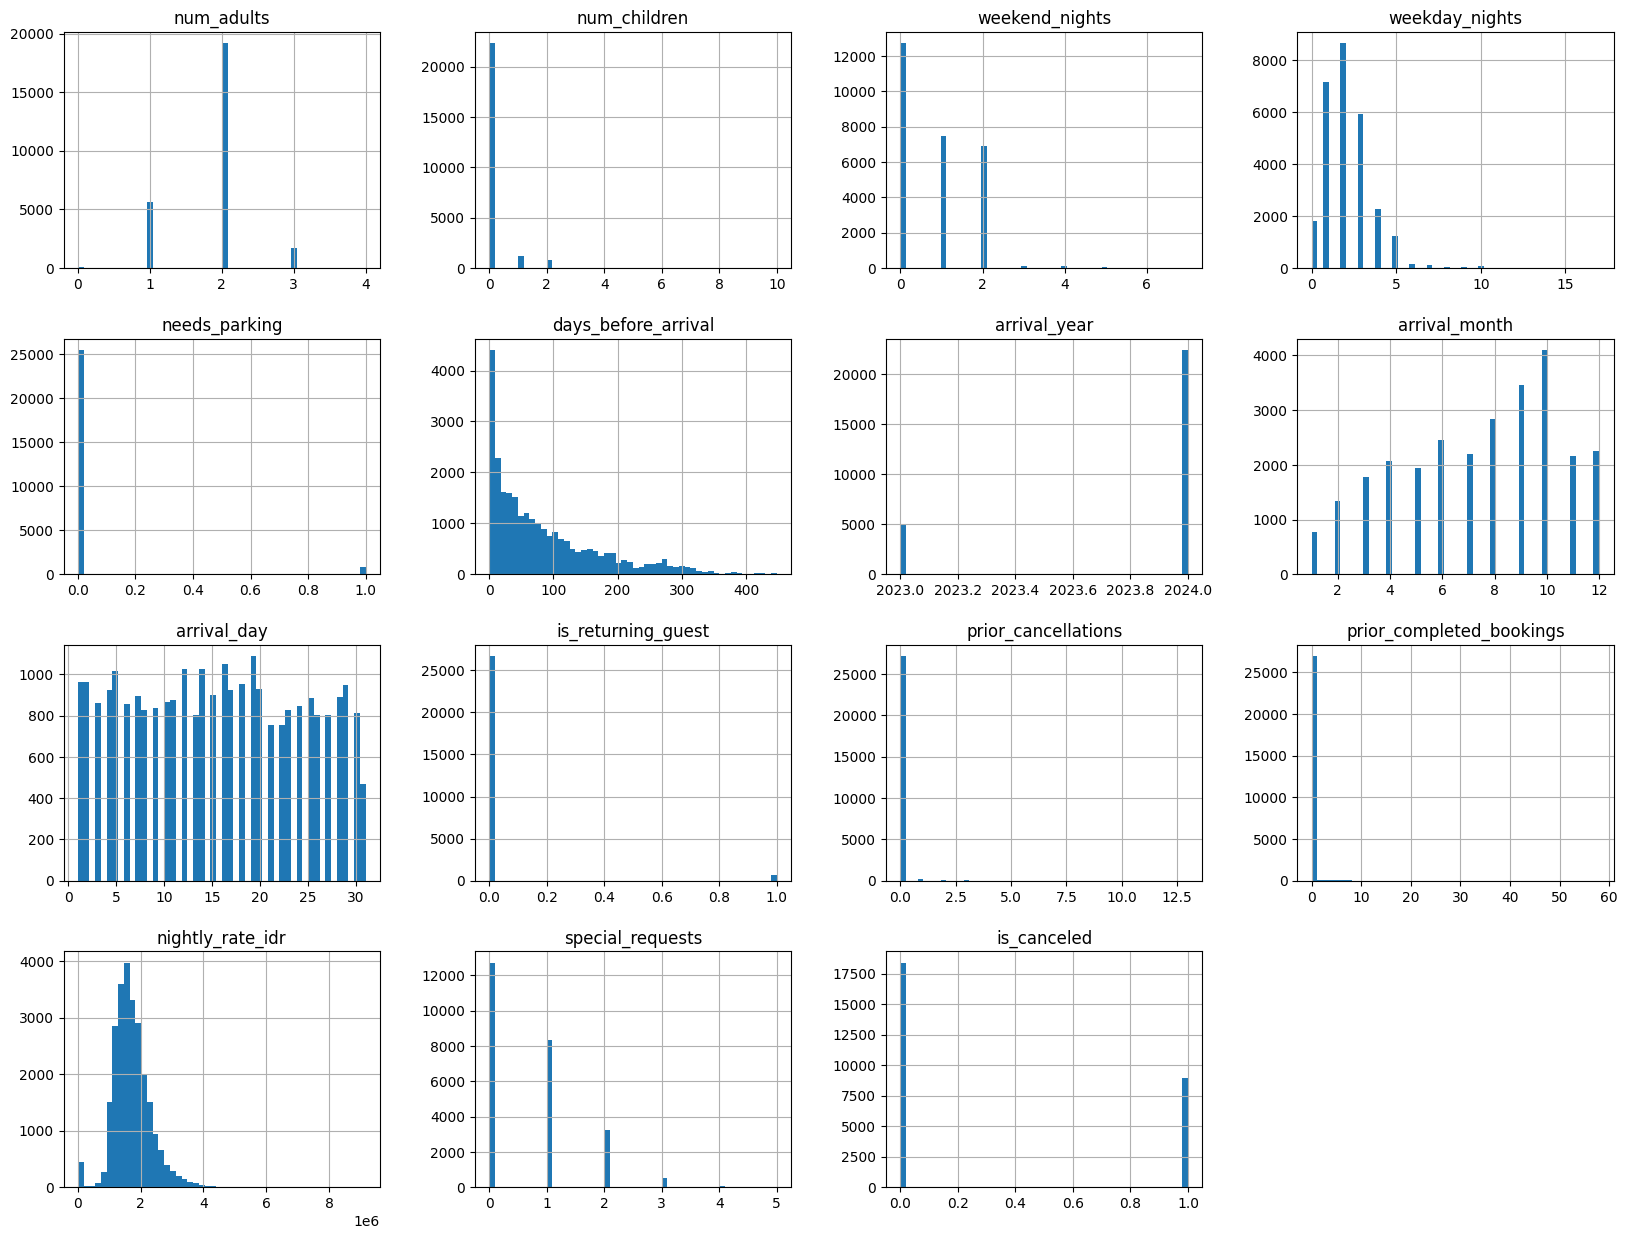

In [3]:
train_df.hist(bins=50, figsize=(20,15))
plt.show()

In [4]:
print('Standard Correlation Coefficient (Pearson\'s r)')

corr_matrix = train_df.corr(numeric_only=True)
corr_matrix['is_canceled'].sort_values(ascending = False)

Standard Correlation Coefficient (Pearson's r)


is_canceled                 1.000000
days_before_arrival         0.440316
arrival_year                0.179826
nightly_rate_idr            0.134092
weekday_nights              0.097226
num_adults                  0.088446
weekend_nights              0.060797
num_children                0.030856
arrival_day                 0.020005
arrival_month              -0.015912
prior_cancellations        -0.035006
prior_completed_bookings   -0.058894
needs_parking              -0.085504
is_returning_guest         -0.107207
special_requests           -0.257996
Name: is_canceled, dtype: float64

## Data Cleaning

### Missing Value Handling

In [5]:
# referensi: https://www.kaggle.com/code/alexisbcook/handling-missing-values

# ========== MISSING VALUE HANDLING ==========
# ===== Show missing values =====
# 1. Train DF
print('Train DF Missing Values')
total_cells = np.prod(train_df.shape)
missing_values_count = train_df.isnull().sum()
# print(missing_values_count)
total_missing = missing_values_count.sum()
percent_missing = (total_missing/total_cells) * 100
print(f'Total missing values = {missing_values_count.sum()}. Missing percentage = {percent_missing}%\n\n')

# 2. Test DF
print('Test DF Missing Values')
total_cells = np.prod(test_df.shape)
missing_values_count = test_df.isnull().sum()
# print(missing_values_count)
total_missing = missing_values_count.sum()
percent_missing = (total_missing/total_cells) * 100
print(f'Total missing values = {missing_values_count.sum()}. Missing percentage = {percent_missing}%\n\n')

# cek hasil jika drop missing values di train_df
train_df_cleaned = train_df.copy()
train_df_cleaned = train_df_cleaned.dropna()
print(f'Training dataset sebelum drop missing vals: {len(train_df)}')
print(f'Training dataset setelah drop missing vals: {len(train_df_cleaned)}\n\n')

# fungsi untuk mengisi nilai kosong pada dataframe
def clean_df(df, columns, method, train_ref=None):
    if df is None:
        print('df invalid')
    if columns is None:
        print('columns invalid')

    ref = train_ref if train_ref is not None else df

    if method == 'median' or method == 'mode':
        for col in columns:
            if method == 'median':
                filler = ref[col].median()
            if method == 'mode':
                filler = ref[col].mode()[0]
            df[col] = df[col].fillna(filler)
        return df
    else:
        print('method invalid')
        return None


# ===== Clean missing values =====
# 1. Train DF
train_df_cleaned = train_df.copy() # reset dataframe training
numerical_columns = ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 
    'days_before_arrival', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 
    'special_requests']
train_df_cleaned = clean_df(train_df_cleaned, numerical_columns, 'median')

categorical_columns = ['needs_parking', 'arrival_year', 'arrival_month', 'arrival_day', 
    'is_returning_guest', 'meal_package', 'room_category', 'booking_channel']
train_df_cleaned = clean_df(train_df_cleaned, categorical_columns, 'mode')
print(f'Sisa missing train_df values setelah cleaning = {train_df_cleaned.isnull().sum().sum()}')
print(f'Panjang train_df_cleaned setelah cleaning = {len(train_df_cleaned)}')


# 2. Test DF
test_df_cleaned = test_df.copy()
test_df_cleaned = clean_df(test_df_cleaned, numerical_columns, 'median', test_df)
test_df_cleaned = clean_df(test_df_cleaned, categorical_columns, 'mode', test_df)

print(f'Sisa missing test_df values setelah cleaning = {test_df_cleaned.isnull().sum().sum()}')
print(f'Panjang test_df_cleaned setelah cleaning = {len(test_df_cleaned)}\n')

Train DF Missing Values
Total missing values = 13349. Missing percentage = 2.566685958310821%


Test DF Missing Values
Total missing values = 3281. Missing percentage = 2.6633222936554324%


Training dataset sebelum drop missing vals: 27373
Training dataset setelah drop missing vals: 16636


Sisa missing train_df values setelah cleaning = 0
Panjang train_df_cleaned setelah cleaning = 27373
Sisa missing test_df values setelah cleaning = 0
Panjang test_df_cleaned setelah cleaning = 6844



> Karena jumlah data yang terbuang cukup banyak, maka baris dengan missing value tidak sebaiknya dihapus, melainkan diisi dengan median atau modus. 

### Duplicate and Invalid Data Handling

In [6]:
# ========== DUPLICATE VALUES HANDLING ==========
print(f'Nilai ganda training = {train_df.duplicated().sum()}\n\n')


# ========== INVALID VALUE HANDLING ==========
# 1. Train DF
# cek nilai negatif
numeric_train_df = train_df_cleaned.select_dtypes(include='number')
print(f'Jumlah nilai negatif pada data train: {(numeric_train_df<0).sum().sum()}')

# cek nilai yang tidak seharusnya 0
no_adults = (train_df_cleaned['num_adults'] == 0)
print(f'Banyak pesanan tanpa orang dewasa = {no_adults.sum()}')
no_nights = ((train_df_cleaned['weekend_nights'] + train_df_cleaned['weekday_nights']) == 0)
print(f'Banyak pesanan dengan jumlah malam 0 = {no_nights.sum()}')

# cek tanggal invalid
date_df = train_df_cleaned[['arrival_year', 'arrival_month', 'arrival_day']].rename(
    columns={'arrival_year': 'year', 'arrival_month': 'month', 'arrival_day': 'day'}
)
invalid_dates = pd.to_datetime(date_df, errors='coerce').isna()
print(f"Banyak tanggal invalid: {invalid_dates.sum()}")

# hapus data invalid
train_df_cleaned = train_df_cleaned[(numeric_train_df >= 0).all(axis=1)].reset_index(drop=True)
valid_mask = (
    (~no_adults) &
    (~no_nights) &
    (~invalid_dates)
)

train_df_cleaned = train_df_cleaned[valid_mask].reset_index(drop=True)
print(f'Panjang train_df_cleaned setelah hapus data invalid = {len(train_df_cleaned)}')

# 2. Test DF
# cek nilai negatif
numeric_test_df = test_df_cleaned.select_dtypes(include='number')
print(f'Jumlah nilai negatif pada data test: {(numeric_test_df<0).sum().sum()}')

# cek nilai yang tidak seharusnya 0
no_adults = (test_df_cleaned['num_adults'] == 0)
print(f'Banyak pesanan tanpa orang dewasa = {no_adults.sum()}')
no_nights = ((test_df_cleaned['weekend_nights'] + test_df_cleaned['weekday_nights']) == 0)
print(f'Banyak pesanan dengan jumlah malam 0 = {no_nights.sum()}')

# cek tanggal invalid
date_df = test_df_cleaned[['arrival_year', 'arrival_month', 'arrival_day']].rename(
    columns={'arrival_year': 'year', 'arrival_month': 'month', 'arrival_day': 'day'}
)
invalid_dates = pd.to_datetime(date_df, errors='coerce').isna()
print(f"Banyak tanggal invalid: {invalid_dates.sum()}")

# isi data invalid dengan median
# Karena untuk test_df, baris tidak boleh dihapus
median_train_adults = train_df_cleaned['num_adults'].median()
test_df_cleaned.loc[no_adults, 'num_adults'] = median_train_adults

median_weekday_nights = train_df_cleaned['weekday_nights'].median()
test_df_cleaned.loc[no_nights, 'weekday_nights'] = median_weekday_nights

print(f'Panjang test_df_cleaned setelah fill data invalid = {len(test_df_cleaned)}')

Nilai ganda training = 0


Jumlah nilai negatif pada data train: 0
Banyak pesanan tanpa orang dewasa = 106
Banyak pesanan dengan jumlah malam 0 = 64
Banyak tanggal invalid: 0
Panjang train_df_cleaned setelah hapus data invalid = 27203
Jumlah nilai negatif pada data test: 0
Banyak pesanan tanpa orang dewasa = 22
Banyak pesanan dengan jumlah malam 0 = 9
Banyak tanggal invalid: 0
Panjang test_df_cleaned setelah fill data invalid = 6844


> Di sisi lain, jumlah data invalid cukup sedikit (< 200 baris), sehingga dihapus tidak masalah.

## Data Transformation

### Categorical Data Encoding

In [7]:
# encoding categorical jadi numerical
train_df_encoded = train_df_cleaned.copy()
test_df_encoded = test_df_cleaned.copy()

ordinal_maps = {
    'meal_package': {'Room Only': 1, 'Breakfast': 2, 'Half Board': 3, 'Full Board': 4}
}
for col, mapping in ordinal_maps.items():
    train_df_encoded[col] = train_df_encoded[col].map(mapping)
    test_df_encoded[col] = test_df_encoded[col].map(mapping)

# reference: https://www.kaggle.com/discussions/getting-started/114797
# room category harus dilakukan one hot encoding karena "show no order or quality"
# booking channel diasumsikan juga demikian
train_df_encoded = pd.get_dummies(train_df_encoded, columns=['room_category', 'booking_channel'], drop_first=True)
test_df_encoded = pd.get_dummies(test_df_encoded, columns=['room_category', 'booking_channel'], drop_first=True)

print("Hasil encoding train_df:")
print(train_df_encoded.head(5))
print("Hasil encoding test_df:")
print(test_df_encoded.head(5))

Hasil encoding train_df:
         id  num_adults  num_children  weekend_nights  weekday_nights  \
0  57152f82         2.0           0.0               1               2   
1  af2ec71b         2.0           0.0               2               1   
2  5d5469ab         3.0           0.0               1               2   
3  d2df0369         2.0           1.0               2               1   
4  91d253db         2.0           0.0               0               1   

   meal_package  needs_parking  days_before_arrival  arrival_year  \
0             2            0.0                 88.0          2024   
1             3            0.0                120.0          2023   
2             2            0.0                209.0          2024   
3             2            0.0                 93.0          2024   
4             1            0.0                 14.0          2024   

   arrival_month  ...  room_category_Type B  room_category_Type C  \
0              4  ...                  True         

### Scaling \(Standardization\)

In [8]:
# Gunakan StandardScaler() dengan asumsi data numerik terdistribusi normal
# reference: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

scaler = StandardScaler()
train_df_encoded[numerical_columns] = scaler.fit_transform(train_df_encoded[numerical_columns])
test_df_encoded[numerical_columns] = scaler.fit_transform(test_df_encoded[numerical_columns])

print(train_df_encoded.head())
print(test_df_encoded.head())

train_df_encoded.describe()
test_df_encoded.describe()

         id  num_adults  num_children  weekend_nights  weekday_nights  \
0  57152f82    0.285848     -0.251437        0.209944       -0.148402   
1  af2ec71b    0.285848     -0.251437        1.352625       -0.853182   
2  5d5469ab    2.291504     -0.251437        0.209944       -0.148402   
3  d2df0369    0.285848      2.342362        1.352625       -0.853182   
4  91d253db    0.285848     -0.251437       -0.932737       -0.853182   

   meal_package  needs_parking  days_before_arrival  arrival_year  \
0             2            0.0             0.044166          2024   
1             3            0.0             0.423374          2023   
2             2            0.0             1.478044          2024   
3             2            0.0             0.103418          2024   
4             1            0.0            -0.832750          2024   

   arrival_month  ...  room_category_Type B  room_category_Type C  \
0              4  ...                  True                 False   
1       

,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
count,6.844000e+03,6.844000e+03,6.844000e+03,6.844000e+03,6844.000000,6844.000000,6.844000e+03,6844.000000,6844.000000,6844.000000,6844.000000,6.844000e+03,6.844000e+03,6.844000e+03,6.844000e+03
mean,-1.152400e-16,2.309991e-17,-4.983351e-17,1.391185e-16,1.945500,0.032291,2.180216e-17,2023.818235,7.401812,15.702659,0.027323,2.076396e-18,3.633693e-17,-2.086778e-16,4.360432e-17
std,1.000073e+00,1.000073e+00,1.000073e+00,1.000073e+00,0.459474,0.176785,1.000073e+00,0.385679,3.050240,8.681514,0.163035,1.000073e+00,1.000073e+00,1.000073e+00,1.000073e+00
min,-1.700637e+00,-2.657692e-01,-9.276610e-01,-1.603002e+00,1.000000,0.000000,-9.979654e-01,2023.000000,1.000000,1.000000,0.000000,-7.072566e-02,-9.489446e-02,-3.114792e+00,-7.848437e-01
25%,2.893030e-01,-2.657692e-01,-9.276610e-01,-8.770261e-01,2.000000,0.000000,-7.726737e-01,2024.000000,5.000000,8.000000,0.000000,-7.072566e-02,-9.489446e-02,-6.190263e-01,-7.848437e-01
50%,2.893030e-01,-2.657692e-01,2.368496e-01,-1.510505e-01,2.000000,0.000000,-3.220902e-01,2024.000000,8.000000,16.000000,0.000000,-7.072566e-02,-9.489446e-02,-1.195086e-01,-7.848437e-01
75%,2.893030e-01,-2.657692e-01,1.401360e+00,5.749252e-01,2.000000,0.000000,4.367874e-01,2024.000000,10.000000,23.000000,0.000000,-7.072566e-02,-9.489446e-02,4.729852e-01,4.965185e-01
max,4.269182e+00,7.219517e+00,6.059403e+00,1.073858e+01,4.000000,1.000000,4.254890e+00,2024.000000,12.000000,31.000000,1.000000,2.919720e+01,2.755270e+01,7.276636e+00,5.621967e+00


### Imbalanced Data Handling

In [9]:
# Gunakan SMOTE untuk menambah data class yang imba
# hanya terapkan untuk training dataset
# Pisahkan X dan y
X_train_encoded = train_df_encoded.drop(columns=['is_canceled', 'id']).copy()
y_train_encoded = train_df_encoded['is_canceled'].copy()

X_train_balanced = X_train_encoded
y_train_balanced = y_train_encoded

print(f"Data sebelum SMOTE: {y_train_balanced.value_counts().to_dict()}")

# Terapkan SMOTE
smote = SMOTE(random_state=RANDOM_STATE)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_encoded, y_train_encoded)

print(f"Data setelah SMOTE: {y_train_balanced.value_counts().to_dict()}")

Data sebelum SMOTE: {0: 18268, 1: 8935}
Data setelah SMOTE: {1: 18268, 0: 18268}


## Feature Selection

In [10]:
# Feature selection sebenarnya ada filter dan wrapper, tapi untuk ini dilakukan filter dulu
# TODO: tambahkan metode feature selection tipe wrapper saat modeling

selector = SelectKBest(score_func=f_classif, k=10)
X_train_selected = selector.fit_transform(X_train_balanced, y_train_balanced)

feature_summary = pd.DataFrame({
    'Feature': X_train_balanced.columns,
    'Score': selector.scores_
}).sort_values(by='Score', ascending=False).reset_index(drop=True)

print("Features score (sorted):")
print(feature_summary)

selected_features = feature_summary.head(15)['Feature'].tolist()
X_train_final = X_train_balanced[selected_features]

X_test_final = test_df_encoded[selected_features]

Features score (sorted):
                                Feature        Score
0                   days_before_arrival  8181.966056
1                      special_requests  3390.638722
2                          arrival_year  1501.950908
3                      nightly_rate_idr   706.346058
4                    is_returning_guest   659.003064
5   booking_channel_Online Travel Agent   577.382680
6             booking_channel_Corporate   553.534144
7                         needs_parking   376.244815
8                            num_adults   348.102839
9                        weekday_nights   337.318398
10        booking_channel_Complimentary   289.500918
11             prior_completed_bookings   194.192925
12                       weekend_nights   134.870212
13                  prior_cancellations    69.925067
14                         num_children    38.969722
15                 room_category_Type G    36.604861
16        booking_channel_Offline Agent    30.063945
17                   

## Dimensionality Reduction

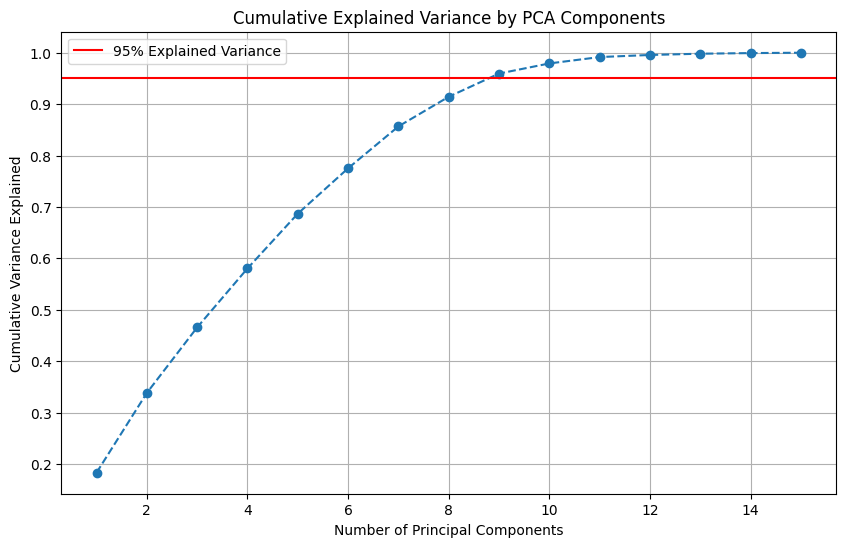

Dimensi sebelum PCA (hasil feature selection): 15
Dimensi setelah PCA (mempertahankan 95% varians): 9


/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/opt/homebrew/Caskroom/minic

In [11]:
# Jika dataset memiliki jumlah fitur yang besar, reduksi dimensi dapat digunakan untuk mengurangi dimensi tanpa
# kehilangan informasi penting. Teknik seperti Principal Component Analysis (PCA) sering digunakan pada tahap ini.

pca_eval = PCA(random_state=RANDOM_STATE)
pca_eval.fit(X_train_final)

cumulative_variance = np.cumsum(pca_eval.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Explained')
plt.legend()
plt.grid(True)
plt.show()

pca_final = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca_final.fit_transform(X_train_final)

print(f"Dimensi sebelum PCA (hasil feature selection): {X_train_final.shape[1]}")
print(f"Dimensi setelah PCA (mempertahankan 95% varians): {X_train_pca.shape[1]}")

X_test_pca = pca_final.transform(X_test_final)

## Modeling and Validation

### Naive Bayes

Naive Bayes memilih kelas $c$ yang memaksimalkan $P(c)\prod_j P(x_j \mid c)$. Implementasi di `src/naive_bayes.py` mendukung dua jenis fitur:

- **Kategorikal**: $P(x_j = v \mid c) = \dfrac{n_{c,v} + \alpha}{n_c + \alpha K_j}$ (Laplace smoothing). Satu slot tambahan disiapkan untuk nilai yang tidak muncul saat training.
- **Numerik**: distribusi Gaussian dengan mean dan variansi per kelas.

Nilai kosong (NaN) tidak diimputasi, tetapi dilewati: faktor $P(x_j \mid c)$ untuk fitur yang kosong tidak ikut dikalikan. Ini sama dengan memarginalkan fitur tersebut, sehingga model bisa langsung menerima data yang memiliki missing value. Perhitungan dilakukan dalam log-space agar tidak underflow.

In [12]:
import itertools
import time
from pathlib import Path

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.preprocessing import OrdinalEncoder

from src.naive_bayes import NaiveBayes

#### Gaussian Naive Bayes pada hasil preprocessing bersama

Sebagai pengecekan, model from scratch dalam mode Gaussian (tanpa fitur kategorikal) dibandingkan dengan `GaussianNB` scikit-learn memakai fitur hasil PCA dari tahap preprocessing di atas. Split dan evaluasi mengikuti model lain: hanya baris asli (bukan hasil SMOTE) yang dinilai.

In [13]:
n_orig = len(X_train_encoded)
is_orig = np.arange(len(y_train_balanced)) < n_orig
strat_key = np.asarray(y_train_balanced).astype(int) * 2 + is_orig.astype(int)
X_tr, X_val, y_tr, y_val, orig_tr, orig_val = train_test_split(
    X_train_pca, y_train_balanced, is_orig,
    test_size=0.15, random_state=RANDOM_STATE, stratify=strat_key,
)
y_tr, y_val = np.asarray(y_tr), np.asarray(y_val)

gnb_scratch = NaiveBayes().fit(X_tr, y_tr)
gnb_sklearn = GaussianNB().fit(X_tr, y_tr)

proba_diff = np.abs(gnb_scratch.predict_proba(X_val) - gnb_sklearn.predict_proba(X_val)).max()
print(f'Selisih probabilitas maksimum scratch vs scikit-learn: {proba_diff:.2e}')
for name, model in [('Gaussian NB (scratch)', gnb_scratch), ('Gaussian NB (scikit-learn)', gnb_sklearn)]:
    pred = model.predict(X_val[orig_val])
    acc = accuracy_score(y_val[orig_val], pred)
    f1 = f1_score(y_val[orig_val], pred, average='macro')
    print(f'{name}: accuracy = {acc:.5f}, macro F1 = {f1:.5f}')

Selisih probabilitas maksimum scratch vs scikit-learn: 6.88e-15
Gaussian NB (scratch): accuracy = 0.50429, macro F1 = 0.49762
Gaussian NB (scikit-learn): accuracy = 0.50429, macro F1 = 0.49762


> Hasil scratch identik dengan scikit-learn, tetapi performanya rendah. Komponen PCA adalah kombinasi linear dari fitur one-hot dan numerik yang distribusinya jauh dari normal, sedangkan SMOTE menggeser prior kelas. Karena itu Naive Bayes memakai pipeline fitur sendiri, sama seperti DTL.

#### Fitur khusus Naive Bayes

- Kolom kategorikal dipakai apa adanya (tanpa one-hot), karena NB menghitung tabel frekuensi per nilai.
- Missing value dibiarkan NaN, dan `num_adults = 0` (tidak valid) juga dijadikan NaN.
- Fitur numerik (`lead`, `price`, `nights`, tanggal kedatangan, tanggal booking) didiskretisasi menjadi 20 bin kuantil. Batas bin hanya dihitung dari data train, lalu dipakai ulang untuk data validasi/test. Diskretisasi dipilih karena distribusi fitur ini miring sehingga asumsi Gaussian kurang cocok.
- Tidak memakai SMOTE: metrik Kaggle adalah accuracy, dan NB sudah memakai prior kelas $P(c)$ secara langsung.
- Ditambahkan kandidat **fitur gabungan** (Cartesian product) dari dua fitur, misalnya `lead*year_month`. Ini teknik *semi-naive Bayes* (Pazzani, 1996): dua fitur yang saling bergantung digabung menjadi satu atribut, sehingga dependensinya tidak lagi dilanggar oleh asumsi independensi NB.

In [14]:
nb_numerical = ['lead', 'price', 'nights', 'arrival_date', 'booking_date']
nb_bins = 20


def prepare_nb_features(df):
    date_parts = df[['arrival_year', 'arrival_month', 'arrival_day']].rename(
        columns={'arrival_year': 'year', 'arrival_month': 'month', 'arrival_day': 'day'}
    )
    arrival = pd.to_datetime(date_parts, errors='coerce')

    X = pd.DataFrame(index=df.index)
    X['meal'] = df['meal_package']
    X['room'] = df['room_category']
    X['channel'] = df['booking_channel']
    X['parking'] = df['needs_parking']
    X['year'] = df['arrival_year']
    X['month'] = df['arrival_month']
    X['year_month'] = df['arrival_year'].astype(str) + '-' + df['arrival_month'].astype(str).str.zfill(2)
    X['weekday'] = arrival.dt.dayofweek
    X['returning'] = df['is_returning_guest']
    X['requests'] = df['special_requests']
    X['adults'] = df['num_adults'].mask(df['num_adults'] == 0)
    X['children'] = df['num_children'].clip(upper=3)
    X['weekend_nights'] = df['weekend_nights'].clip(upper=4)
    X['weekday_nights'] = df['weekday_nights'].clip(upper=7)
    X['prior_cancel'] = (df['prior_cancellations'] > 0).astype(int)
    X['prior_booking'] = (df['prior_completed_bookings'] > 0).astype(int)
    X['lead'] = df['days_before_arrival']
    X['price'] = df['nightly_rate_idr']
    X['nights'] = df['weekend_nights'] + df['weekday_nights']
    X['arrival_date'] = (arrival - pd.Timestamp('2023-01-01')).dt.days
    X['booking_date'] = X['arrival_date'] - df['days_before_arrival']
    return X


def fit_bins(X):
    quantiles = np.linspace(0, 1, nb_bins + 1)[1:-1]
    return {c: np.unique(np.nanquantile(X[c].astype(float), quantiles)) for c in nb_numerical}


def apply_bins(X, edges):
    X = X.copy()
    for c in nb_numerical:
        values = X[c].astype(float)
        X[c] = np.where(values.isna(), np.nan, np.digitize(values, edges[c]))
    return X


def add_pairs(X, pairs):
    joined = {}
    for a, b in pairs:
        value = X[a].astype(str) + '|' + X[b].astype(str)
        joined[f'{a}*{b}'] = value.where(X[a].notna() & X[b].notna(), np.nan)
    return pd.concat([X, pd.DataFrame(joined, index=X.index)], axis=1)


def nb_transform(X, edges):
    return add_pairs(apply_bins(X, edges), nb_pairs)


nb_X = prepare_nb_features(train_df)
nb_y = train_df['is_canceled'].values
nb_single = list(nb_X.columns)
nb_pair_base = [
    'lead', 'year_month', 'requests', 'channel', 'price', 'room', 'weekend_nights', 'weekday_nights',
    'adults', 'children', 'meal', 'parking', 'returning', 'nights', 'month', 'weekday',
    'booking_date', 'arrival_date',
]
nb_pairs = list(itertools.combinations(nb_pair_base, 2))

nb_X_train, nb_X_val, nb_y_train, nb_y_val = train_test_split(
    nb_X, nb_y, test_size=0.2, stratify=nb_y, random_state=RANDOM_STATE
)
print(f'Train: {len(nb_X_train)} baris, validasi: {len(nb_X_val)} baris')
print(f'Kandidat fitur: {len(nb_single)} tunggal + {len(nb_pairs)} gabungan')

Train: 21898 baris, validasi: 5475 baris
Kandidat fitur: 21 tunggal + 153 gabungan


#### Feature selection (wrapper: greedy forward selection)

Karena NB mengalikan likelihood setiap fitur, fitur yang redundan akan "dihitung dua kali" dan membuat probabilitas terlalu yakin. Maka fitur dipilih dengan *forward selection*: mulai dari himpunan kosong, setiap langkah ditambahkan satu fitur yang paling menaikkan accuracy 5-fold cross-validation, berhenti jika tidak ada kenaikan (maksimal 8 fitur). Seleksi hanya dilakukan di bagian train, sedangkan data validasi disimpan untuk evaluasi akhir.

Semua fitur tunggal tanpa seleksi -> CV accuracy = 0.73345


+ lead*year_month              CV accuracy = 0.76957  (2 s)


+ requests*channel             CV accuracy = 0.80907  (7 s)


+ channel*weekday_nights       CV accuracy = 0.81108  (14 s)


+ price*meal                   CV accuracy = 0.81268  (22 s)


+ weekend_nights*parking       CV accuracy = 0.81368  (33 s)


+ room*children                CV accuracy = 0.81501  (46 s)


+ children                     CV accuracy = 0.81537  (60 s)



Fitur terpilih: ['lead*year_month', 'requests*channel', 'channel*weekday_nights', 'price*meal', 'weekend_nights*parking', 'room*children', 'children']


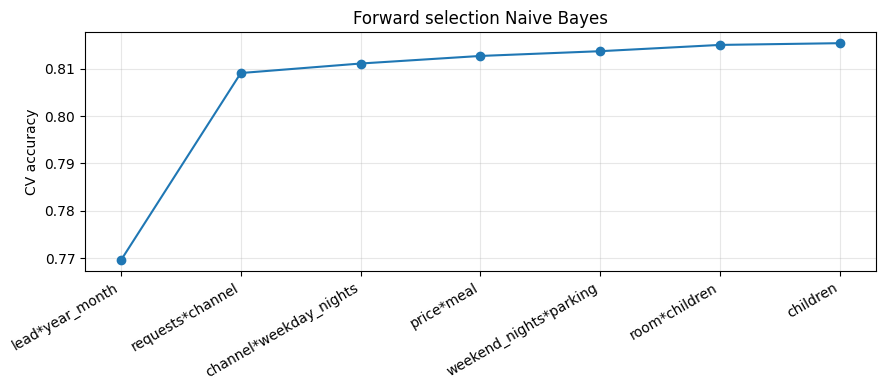

In [15]:
nb_folds = []
nb_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for tr_idx, va_idx in nb_skf.split(nb_X_train, nb_y_train):
    edges = fit_bins(nb_X_train.iloc[tr_idx])
    nb_folds.append((
        nb_transform(nb_X_train.iloc[tr_idx], edges), nb_y_train[tr_idx],
        nb_transform(nb_X_train.iloc[va_idx], edges), nb_y_train[va_idx],
    ))


def cv_accuracy(features, alpha=1.0):
    scores = []
    for X_a, y_a, X_b, y_b in nb_folds:
        model = NaiveBayes(categorical_features=range(len(features)), alpha=alpha)
        model.fit(X_a[features].values, y_a)
        scores.append(accuracy_score(y_b, model.predict(X_b[features].values)))
    return np.mean(scores)


print(f'Semua fitur tunggal tanpa seleksi -> CV accuracy = {cv_accuracy(nb_single):.5f}')

nb_candidates = list(nb_folds[0][0].columns)
nb_features = []
nb_history = []
nb_best_score = 0
start = time.time()
while len(nb_features) < 8:
    scores = [(cv_accuracy(nb_features + [c]), c) for c in nb_candidates if c not in nb_features]
    score, feature = max(scores)
    if score <= nb_best_score:
        break
    nb_features.append(feature)
    nb_history.append(score)
    nb_best_score = score
    print(f'+ {feature:28s} CV accuracy = {score:.5f}  ({time.time() - start:.0f} s)')

print(f'\nFitur terpilih: {nb_features}')

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(nb_history) + 1), nb_history, marker='o')
plt.xticks(range(1, len(nb_history) + 1), nb_features, rotation=30, ha='right')
plt.ylabel('CV accuracy')
plt.title('Forward selection Naive Bayes')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Tuning Laplace smoothing $\alpha$

In [16]:
nb_alpha_scores = {alpha: cv_accuracy(nb_features, alpha) for alpha in [0.1, 0.5, 1, 2, 5, 10]}
for alpha, score in nb_alpha_scores.items():
    print(f'alpha = {alpha:<4} -> CV accuracy = {score:.5f}')
nb_alpha = max(nb_alpha_scores, key=nb_alpha_scores.get)
print(f'alpha terpilih: {nb_alpha}')

alpha = 0.1  -> CV accuracy = 0.81505
alpha = 0.5  -> CV accuracy = 0.81528
alpha = 1    -> CV accuracy = 0.81537
alpha = 2    -> CV accuracy = 0.81391
alpha = 5    -> CV accuracy = 0.81172
alpha = 10   -> CV accuracy = 0.80816
alpha terpilih: 1


#### Perbandingan dengan scikit-learn

Pembanding yang setara adalah `CategoricalNB`. Karena `CategoricalNB` tidak menerima NaN, missing value di-encode menjadi kategori tersendiri (`'nan'`), dan nilai yang tidak muncul di train diberi kode kategori tambahan.

                       Model  Accuracy  Precision   Recall  F1 (Canceled=1)  Macro F1
       Naive Bayes (scratch)  0.818447   0.740096 0.687291         0.712717  0.790003
CategoricalNB (scikit-learn)  0.818995   0.738279 0.693423         0.715148  0.791251

Prediction agreement: 98.74%

--- Classification Report: Naive Bayes (scratch) ---
              precision    recall  f1-score   support

           0     0.8527    0.8824    0.8673      3681
           1     0.7401    0.6873    0.7127      1794

    accuracy                         0.8184      5475
   macro avg     0.7964    0.7848    0.7900      5475
weighted avg     0.8158    0.8184    0.8166      5475



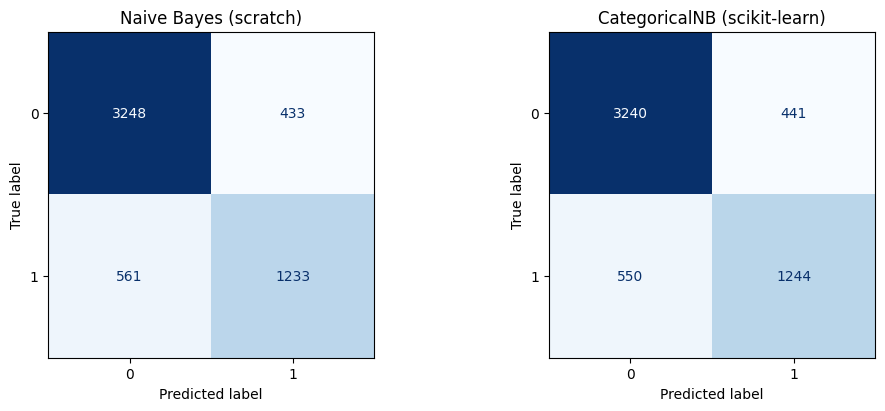

In [17]:
nb_edges = fit_bins(nb_X_train)
nb_A = nb_transform(nb_X_train, nb_edges)[nb_features]
nb_B = nb_transform(nb_X_val, nb_edges)[nb_features]

nb_model = NaiveBayes(categorical_features=range(len(nb_features)), alpha=nb_alpha)
nb_model.fit(nb_A.values, nb_y_train)
nb_val_pred = nb_model.predict(nb_B.values)

nb_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
sk_A = nb_encoder.fit_transform(nb_A.astype(str))
sk_B = nb_encoder.transform(nb_B.astype(str))
n_categories = np.array([len(c) for c in nb_encoder.categories_])
sk_B = np.where(sk_B < 0, n_categories, sk_B)

sk_nb = CategoricalNB(alpha=nb_alpha, min_categories=n_categories + 1).fit(sk_A, nb_y_train)
sk_val_pred = sk_nb.predict(sk_B)


def nb_metrics(name, y_true, y_pred):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 (Canceled=1)': f1_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
    }


nb_comparison = pd.DataFrame([
    nb_metrics('Naive Bayes (scratch)', nb_y_val, nb_val_pred),
    nb_metrics('CategoricalNB (scikit-learn)', nb_y_val, sk_val_pred),
])
print(nb_comparison.to_string(index=False))
print(f'\nPrediction agreement: {(nb_val_pred == sk_val_pred).mean() * 100:.2f}%')

print('\n--- Classification Report: Naive Bayes (scratch) ---')
print(classification_report(nb_y_val, nb_val_pred, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for ax, (name, pred) in zip(axes, [('Naive Bayes (scratch)', nb_val_pred), ('CategoricalNB (scikit-learn)', sk_val_pred)]):
    ConfusionMatrixDisplay.from_predictions(nb_y_val, pred, labels=[0, 1], ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.show()

#### Bonus: graf Naive Bayes

Graf di bawah menunjukkan struktur model: variabel kelas `is_canceled` menjadi parent dari setiap atribut yang dipakai model (asumsi independensi bersyarat), dengan tebal edge sebanding dengan mutual information $I(X_j; C)$ yang dihitung dari tabel probabilitas model. Atribut gabungan dihubungkan (garis putus-putus) ke fitur asalnya untuk menunjukkan dependensi antarfitur yang ditangkap.

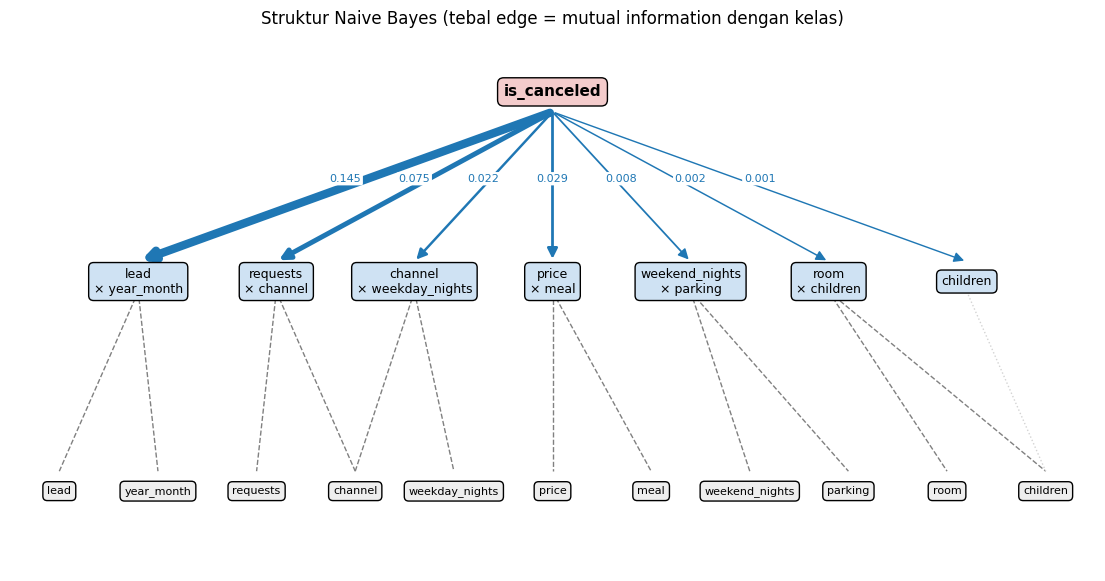

In [18]:
def nb_mutual_information(model, j):
    prior = np.exp(model.class_log_prior_)[:, None]
    conditional = np.exp(model.feature_log_prob_[j])
    joint = prior * conditional
    marginal = joint.sum(axis=0, keepdims=True)
    return float(np.sum(joint * np.log(conditional / marginal)))


def draw_nb_graph(model, features, path):
    mi = [nb_mutual_information(model, j) for j in range(len(features))]
    base = []
    for f in features:
        for part in f.split('*'):
            if part not in base:
                base.append(part)

    fig, ax = plt.subplots(figsize=(14, 7))
    ax.axis('off')
    ax.set_xlim(-0.5, max(len(features), len(base)) - 0.5)
    ax.set_ylim(-0.3, 2.4)
    center = (max(len(features), len(base)) - 1) / 2
    attr_x = np.linspace(center - (len(features) - 1) / 2 * 1.4, center + (len(features) - 1) / 2 * 1.4, len(features))
    base_x = np.linspace(center - (len(base) - 1) / 2, center + (len(base) - 1) / 2, len(base))
    box = dict(boxstyle='round,pad=0.4', ec='black')

    for x, f, m in zip(attr_x, features, mi):
        ax.annotate('', xy=(x, 1.25), xytext=(center, 2.0),
                    arrowprops=dict(arrowstyle='-|>', lw=1 + 5 * m / max(mi), mutation_scale=15, color='tab:blue'))
        ax.text((x + center) / 2, 1.65, f'{m:.3f}', fontsize=8, ha='center', color='tab:blue',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'))
        if '*' in f:
            for part in f.split('*'):
                ax.plot([x, base_x[base.index(part)]], [1.1, 0.2], ls='--', color='gray', lw=1)
        else:
            ax.plot([x, base_x[base.index(f)]], [1.1, 0.2], ls=':', color='lightgray', lw=1)
        ax.text(x, 1.15, f.replace('*', '\n× '), ha='center', va='center', fontsize=9, bbox={**box, 'fc': '#cfe2f3'})
    for x, f in zip(base_x, base):
        ax.text(x, 0.1, f, ha='center', va='center', fontsize=8, bbox={**box, 'fc': '#eeeeee'})
    ax.text(center, 2.1, 'is_canceled', ha='center', va='center', fontsize=11, fontweight='bold', bbox={**box, 'fc': '#f4cccc'})
    ax.set_title('Struktur Naive Bayes (tebal edge = mutual information dengan kelas)')
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()


Path('output').mkdir(exist_ok=True)
draw_nb_graph(nb_model, nb_features, 'output/naive_bayes_graph.png')

## Submission

In [19]:
nb_edges_full = fit_bins(nb_X)
nb_X_full = nb_transform(nb_X, nb_edges_full)[nb_features]
nb_X_test = nb_transform(prepare_nb_features(test_df), nb_edges_full)[nb_features]

nb_final = NaiveBayes(categorical_features=range(len(nb_features)), alpha=nb_alpha)
nb_final.fit(nb_X_full.values, nb_y)

nb_model_path = 'output/naive_bayes.pkl'
nb_final.save(nb_model_path)
nb_loaded = NaiveBayes.load(nb_model_path)
nb_test_pred = nb_loaded.predict(nb_X_test.values)
np.testing.assert_array_equal(nb_final.predict(nb_X_test.values), nb_test_pred)
print(f"Model tersimpan di '{nb_model_path}' dan hasil load memberi prediksi identik")

nb_submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': nb_test_pred.astype(int)})
assert len(nb_submission) == len(sample_submission)
assert list(nb_submission.columns) == list(sample_submission.columns)
assert nb_submission['is_canceled'].isin([0, 1]).all()

nb_submission_path = 'output/submission_naive_bayes.csv'
nb_submission.to_csv(nb_submission_path, index=False)
print(f"{len(nb_submission)} prediksi tersimpan di '{nb_submission_path}'")
print(nb_submission['is_canceled'].value_counts().to_dict())
nb_submission.head()

Model tersimpan di 'output/naive_bayes.pkl' dan hasil load memberi prediksi identik
6844 prediksi tersimpan di 'output/submission_naive_bayes.csv'
{0: 4853, 1: 1991}


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0
